In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import visualizations as mv

d = mv.Data()
df = d.df
print(f"{len(df):,} titles, {df.shape[1]} columns")

64,833 titles, 35 columns


## 1. Dataset overview

What is in the table, how complete it is, and how many titles carry a score.

In [2]:
base = df.drop(columns=["genre_list"])
overview = pd.DataFrame({
    "dtype": base.dtypes.astype(str),
    "pct_missing": base.isna().mean().mul(100).round(1),
    "n_unique": base.nunique(),
}).sort_values("pct_missing", ascending=False)
overview

,dtype,pct_missing,n_unique
background,object,82.4,11430
title_english,object,71.1,18193
themes,object,62.5,1008
score,float64,62.0,409
demographics,object,59.4,13
title_synonyms,object,48.5,32867
serializations,object,33.0,1252
synopsis,object,30.7,44103
chapters,float64,29.0,421
volumes,float64,25.6,77


df[["title", "content_format", "score", "scored_by", "members", "favorites", "pub_year", "genres"]].head(8)

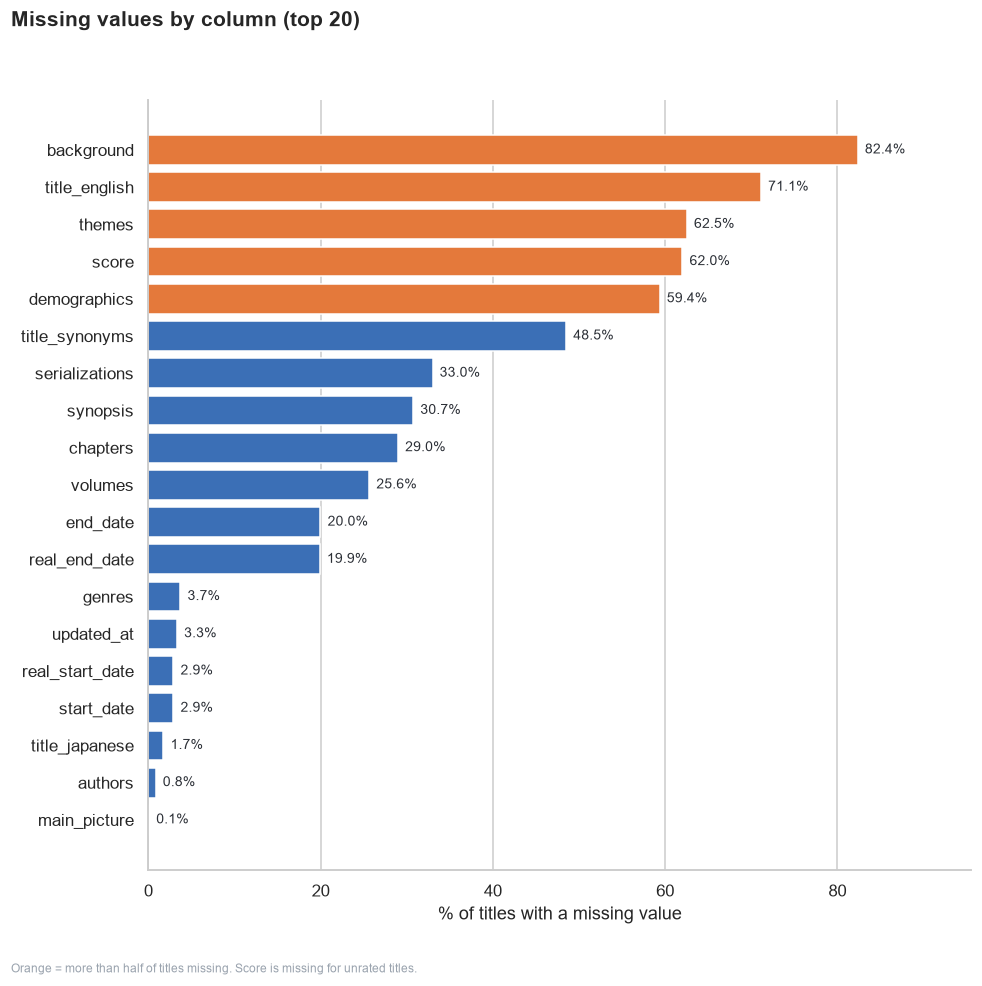

In [3]:
fig = mv.missing_values(d)
plt.show()

## 2. Distributions

In [4]:
numeric = [c for c in mv.NUMERIC_COLS if c in df.columns]
stats = df[numeric].describe(percentiles=[.25, .5, .75, .9, .99]).T.round(2)
stats["skew"] = df[numeric].skew().round(2)
stats

,count,mean,std,min,25%,50%,75%,90%,99%,max,skew
score,24636.0,6.95,0.52,2.44,6.62,6.91,7.25,7.6,8.36,9.47,0.18
scored_by,64833.0,687.00,5514.49,0.00,7.00,46.00,261.00,994.0,9588.68,394362.00,34.38
members,64833.0,1758.76,11083.11,3.00,64.00,190.00,786.00,2728.6,25839.20,643969.00,26.12
favorites,64833.0,54.99,1057.06,0.00,0.00,0.00,3.00,17.0,696.00,119470.00,62.90
chapters,46042.0,21.19,53.90,1.00,5.00,9.00,19.00,48.0,196.00,6477.00,43.69
volumes,48211.0,2.97,4.77,1.00,1.00,1.00,3.00,7.0,23.00,200.00,7.59


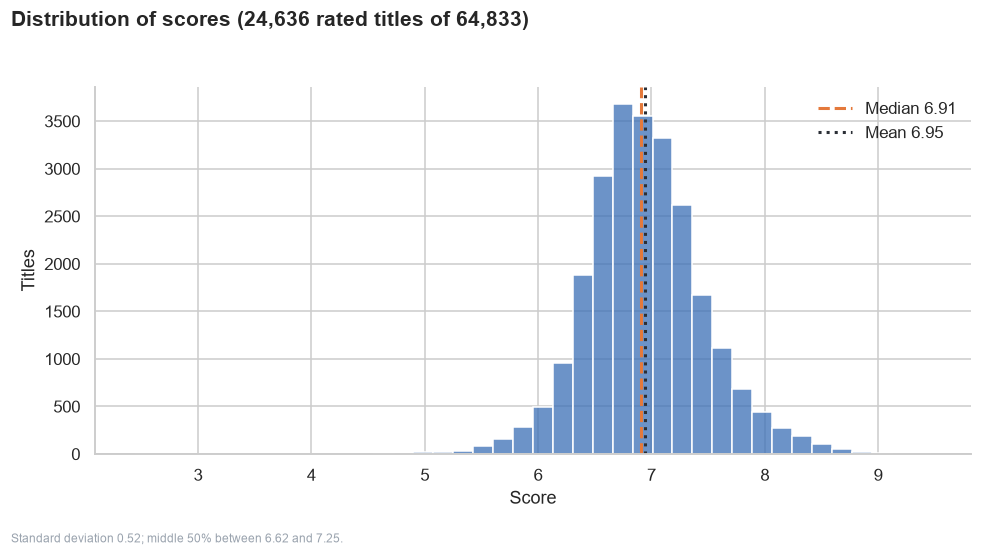

In [5]:
fig = mv.rating_distribution(d)
plt.show()

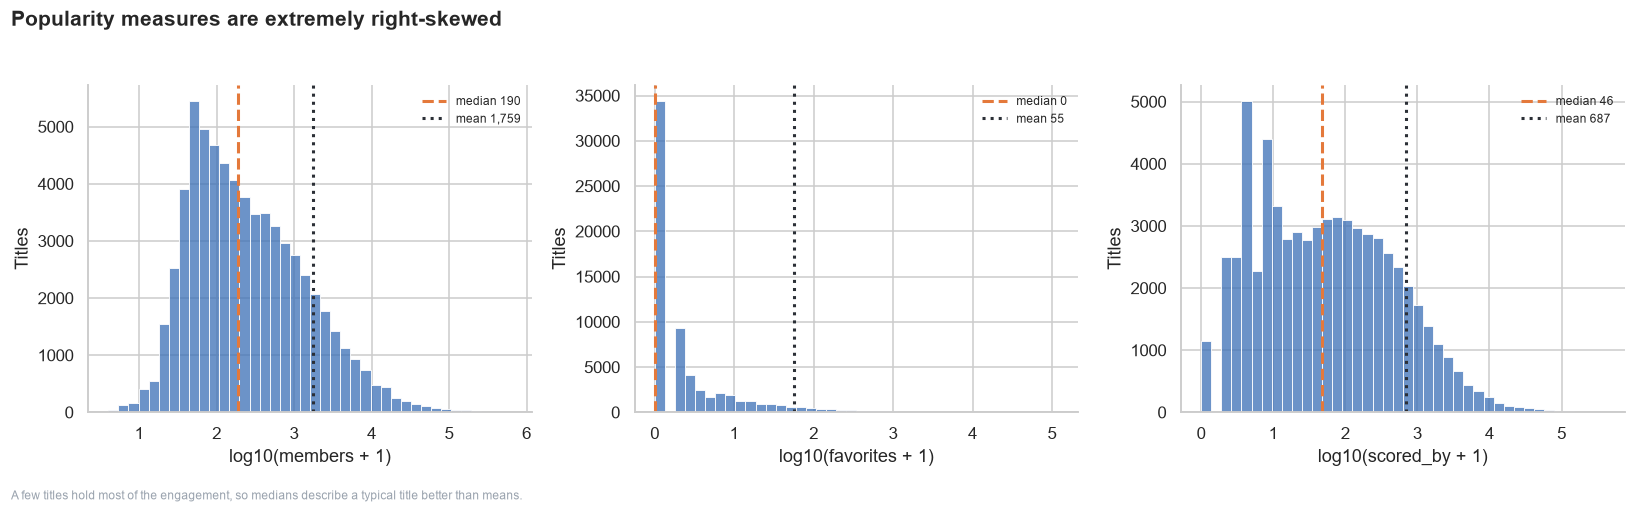

In [6]:
fig = mv.popularity_skew(d)
plt.show()

## 3. Outliers

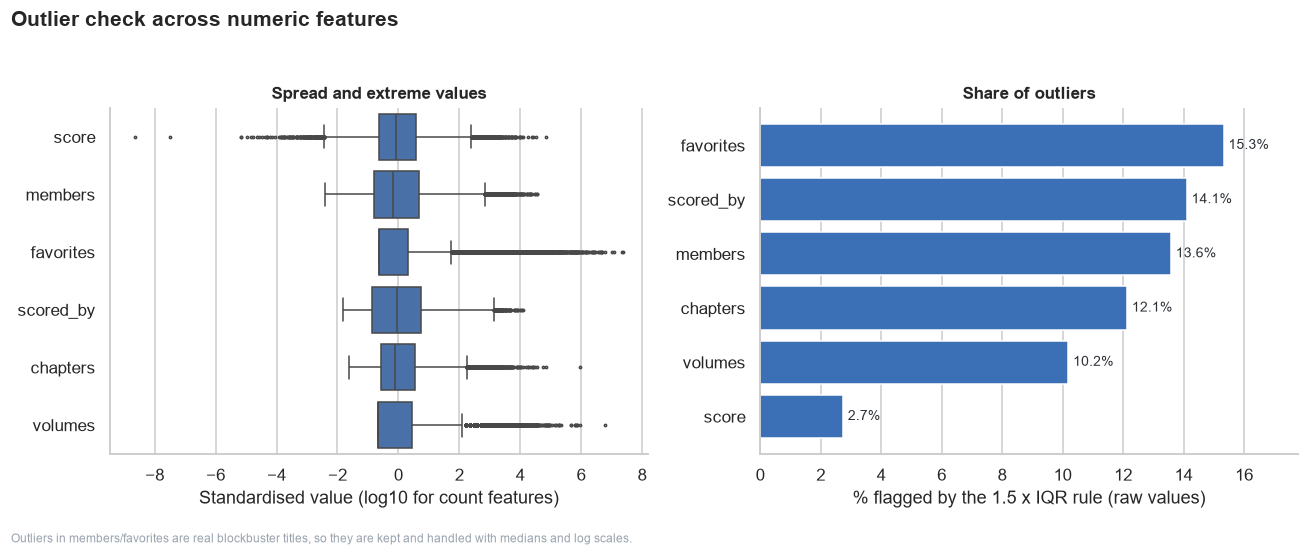

In [7]:
fig = mv.outliers(d)
plt.show()

In [8]:
df.nlargest(10, "members")[["title", "content_format", "score", "members", "favorites"]]

,title,content_format,score,members,favorites
0,Berserk,Manga,9.47,643969.0,119470.0
22,Shingeki no Kyojin,Manga,8.55,635373.0,68609.0
1,One Piece,Manga,9.22,579557.0,111462.0
8,Chainsaw Man,Manga,8.75,569114.0,77718.0
27,Tokyo Ghoul,Manga,8.52,480001.0,43505.0
11,One Punch-Man,Manga,8.75,457481.0,37439.0
15,Solo Leveling,Manhwa,8.68,435457.0,40236.0
179,Boku no Hero Academia,Manga,8.09,424581.0,27809.0
100,Kimetsu no Yaiba,Manga,8.23,414593.0,28428.0
3,Oyasumi Punpun,Manga,9.02,413897.0,49361.0


In [9]:
df[df["scored_by"] >= 100].nsmallest(10, "score")[["title", "content_format", "score", "scored_by", "members"]]

,title,content_format,score,scored_by,members
14521,High School Musical,Manga,2.44,1652.0,2478.0
15319,Zannen nagara Chigaimasu.,One-shot,3.04,1262.0,1768.0
12521,Gal☆Cleaning!,Manga,4.26,4658.0,8435.0
18067,Yobu Koe,One-shot,4.26,631.0,1158.0
19768,School Kill,One-shot,4.36,453.0,672.0
14399,Battle Royale II: Blitz Royale,Manga,4.43,1714.0,3757.0
19211,Sweet My Sisters: Pure Pure,One-shot,4.47,507.0,790.0
19417,Dead Word Puzzle,Manga,4.53,485.0,1025.0
15861,R402,Manga,4.57,1062.0,2474.0
15612,Delivery of the Dead,Manga,4.61,1149.0,2108.0


In [10]:
df.nlargest(10, "chapters")[["title", "content_format", "chapters", "volumes", "status"]]

,title,content_format,chapters,volumes,status
19758,Sazae-san,Manga,6477.0,45.0,finished
5060,Kochira Katsushikaku Kameari Kouenmae Hashutsujo,Manga,1957.0,200.0,finished
12583,Asari-chan,Manga,1738.0,100.0,finished
27126,Denma,Manhwa,1410.0,19.0,finished
60733,3-Second Strip,Manhwa,1333.0,NaN,finished
35781,Nijitte Monogatari,Manga,1254.0,110.0,finished
42111,The Sound of Your Heart,Manhwa,1233.0,NaN,finished
26159,Shizukanaru Don: Yakuza Side Story,Manga,1175.0,108.0,finished
1255,Crayon Shin-chan,Manga,1126.0,50.0,finished
7586,Oishinbo,Manga,1039.0,111.0,on_hiatus


## 4. Content formats

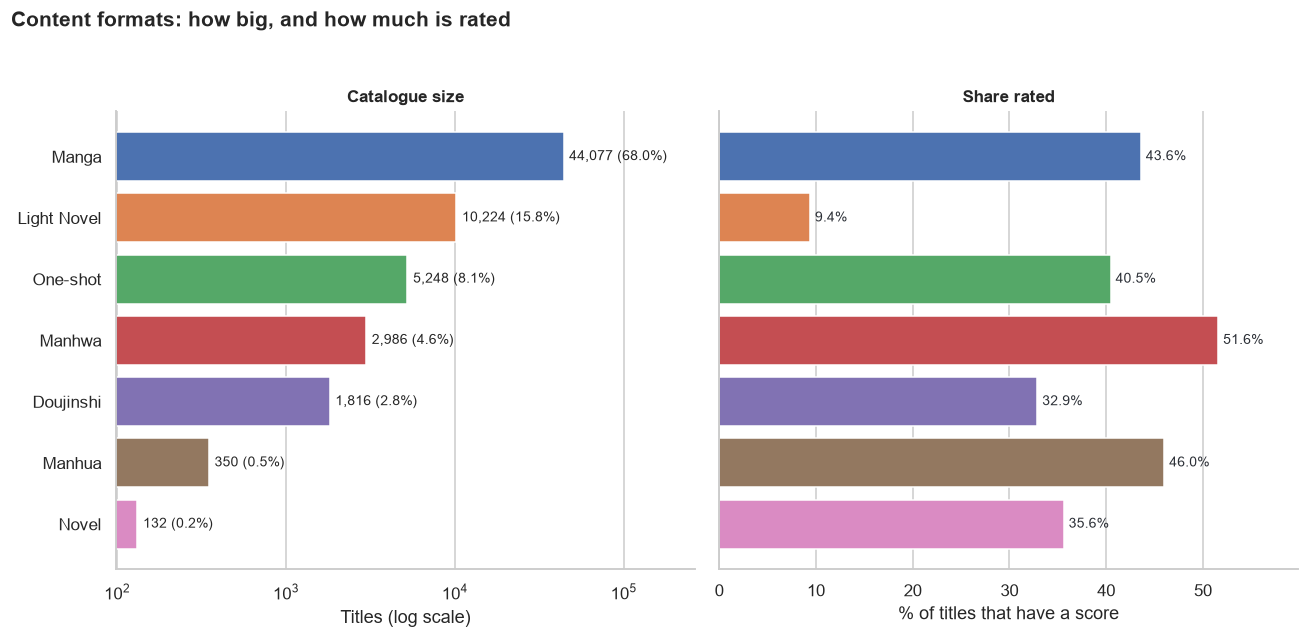

In [11]:
fig = mv.format_composition(d)
plt.show()

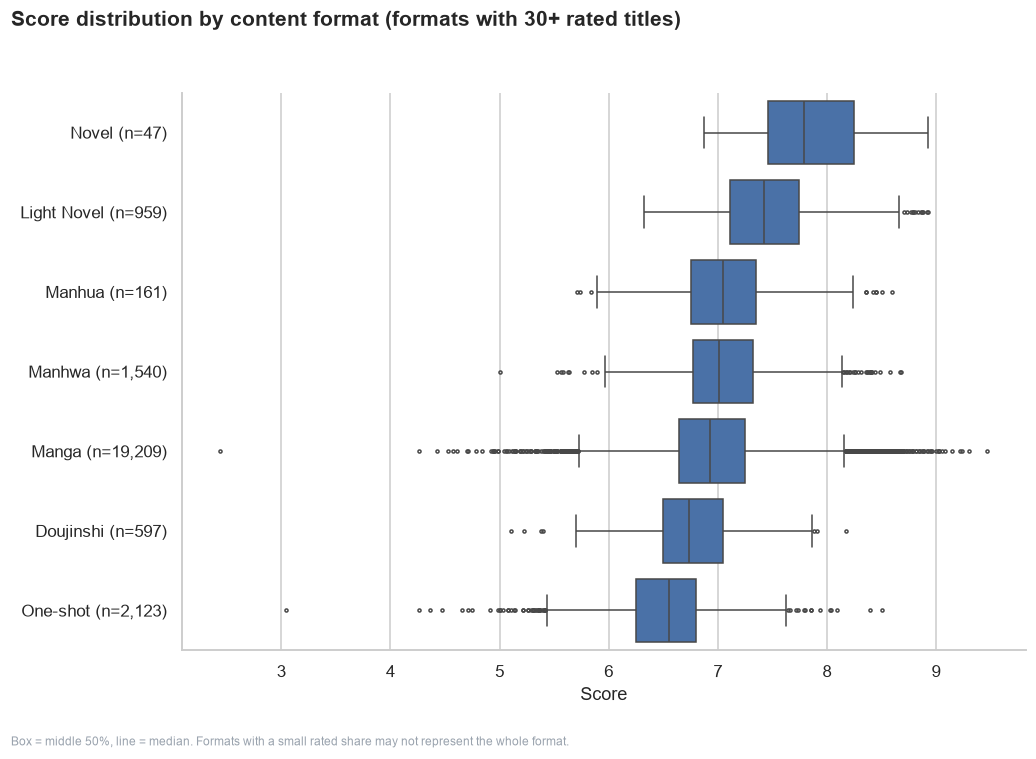

In [12]:
fig = mv.score_by_format(d)
plt.show()

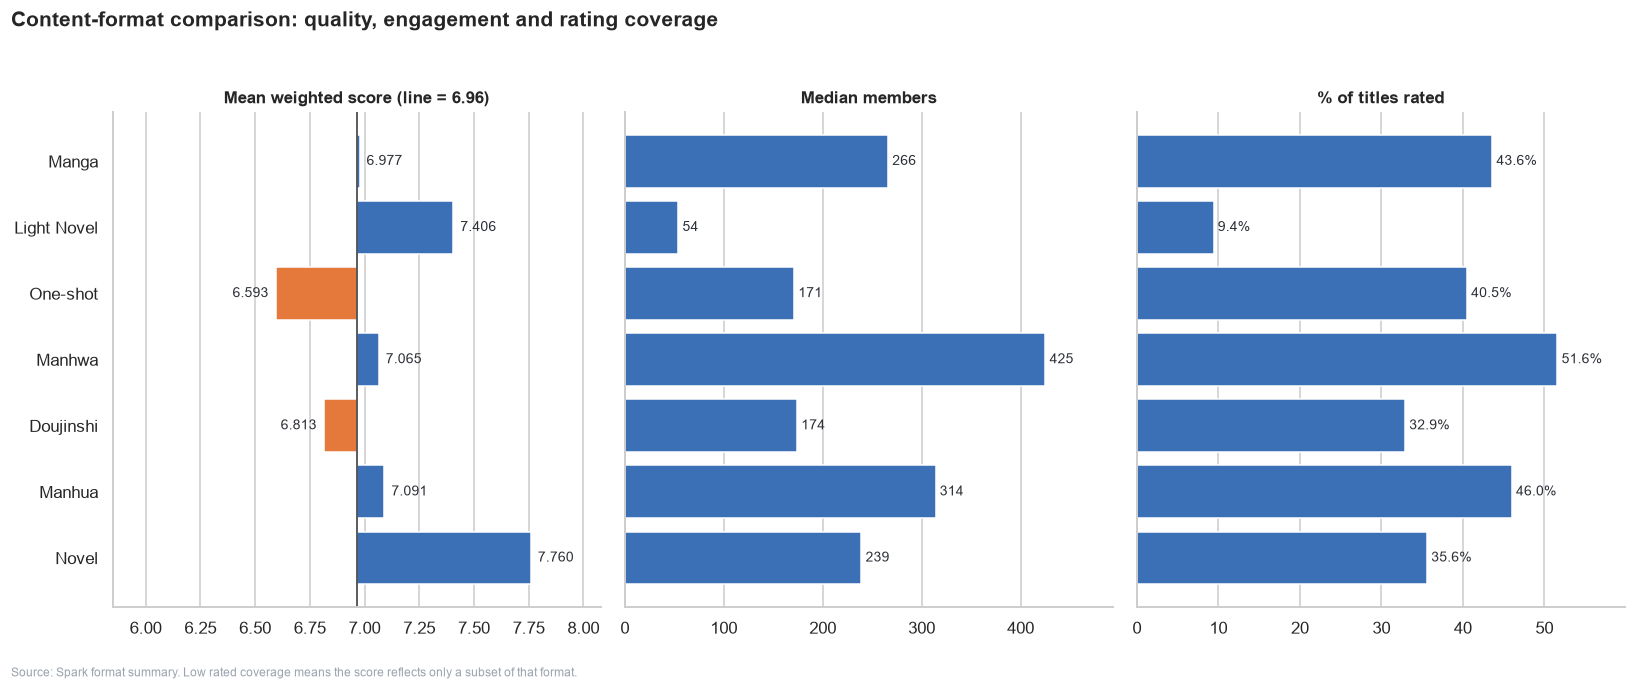

In [13]:
fig = mv.format_comparison(d)
plt.show()

In [14]:
(df.groupby("content_format")
   .agg(titles=("title", "size"), rated=("score", "count"),
        median_score=("score", "median"), median_members=("members", "median"),
        median_chapters=("chapters", "median"))
   .assign(pct_rated=lambda t: (t["rated"] / t["titles"] * 100).round(1))
   .sort_values("titles", ascending=False))

,titles,rated,median_score,median_members,median_chapters,pct_rated
content_format,,,,,,
Manga,44077,19209,6.93,266.0,10.0,43.6
Light Novel,10224,959,7.42,54.0,8.0,9.4
One-shot,5248,2123,6.55,171.0,1.0,40.5
Manhwa,2986,1540,7.01,425.0,57.0,51.6
Doujinshi,1816,597,6.74,174.5,1.0,32.9
Manhua,350,161,7.05,317.0,14.5,46.0
Novel,132,47,7.79,240.5,12.5,35.6


## 5. Genres, themes and demographics

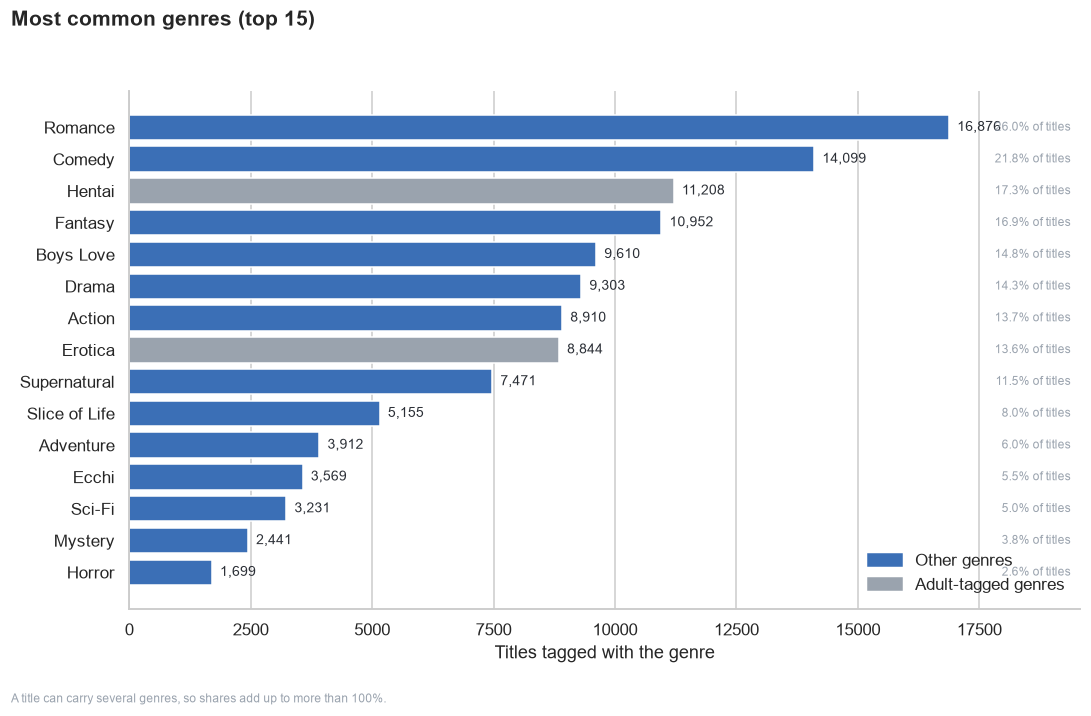

In [15]:
fig = mv.genre_distribution(d)
plt.show()

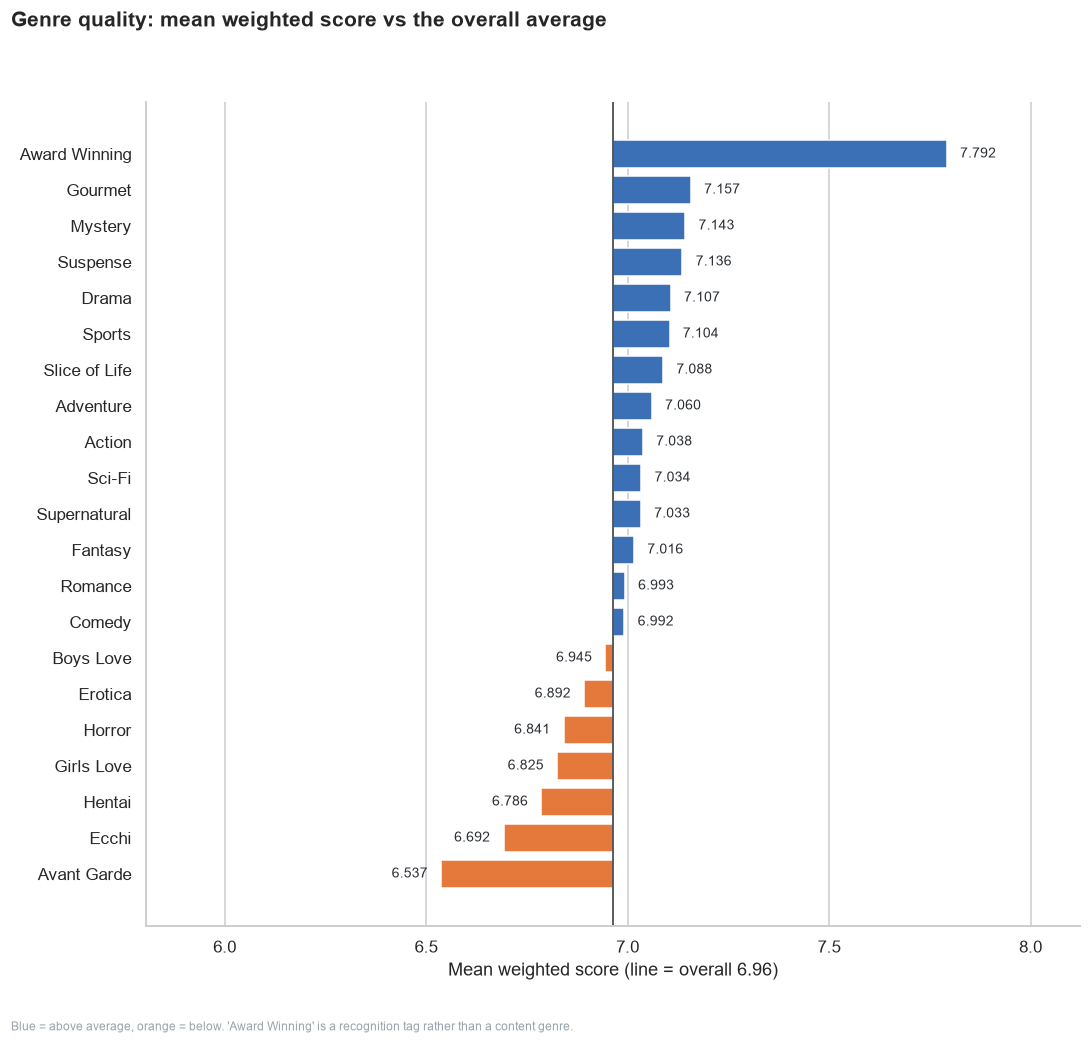

In [16]:
fig = mv.genre_quality(d)
plt.show()

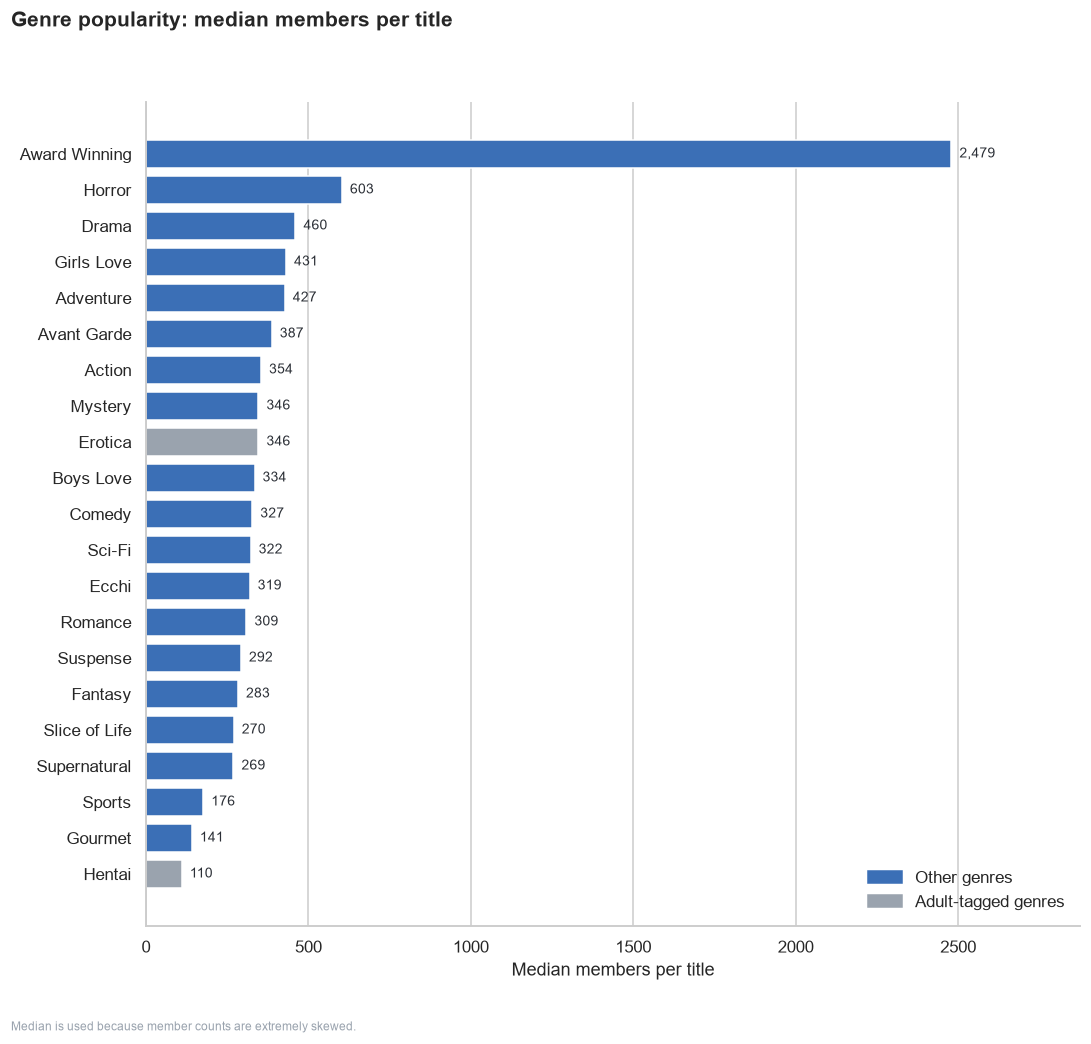

In [17]:
fig = mv.genre_popularity(d)
plt.show()

In [18]:
exploded = df.explode("genre_list").dropna(subset=["genre_list"])
(exploded.groupby("genre_list")
   .agg(titles=("title", "size"), rated=("score", "count"),
        mean_score=("score", "mean"), median_members=("members", "median"))
   .sort_values("titles", ascending=False).round(3).head(15))

,titles,rated,mean_score,median_members
genre_list,,,,
Romance,16876,7806,6.981,310.0
Comedy,14099,6504,6.977,328.0
Hentai,11208,1932,6.728,110.0
Fantasy,10952,4585,7.006,283.5
Boys Love,9610,5154,6.924,335.0
Drama,9303,4997,7.100,460.0
Action,8910,4034,7.028,354.0
Erotica,8844,4823,6.865,346.0
Supernatural,7471,3197,7.021,270.0


In [19]:
(df.groupby("n_genres")
   .agg(titles=("title", "size"), mean_score=("score", "mean"), median_members=("members", "median"))
   .round(3))

,titles,mean_score,median_members
n_genres,,,
0,2412,6.855,90.0
1,24956,6.884,112.0
2,22092,6.934,242.5
3,10755,6.965,426.0
4,3419,7.071,714.0
5,919,7.138,1043.0
6,208,7.132,970.5
7,61,7.419,1365.0
8,8,7.353,245.5


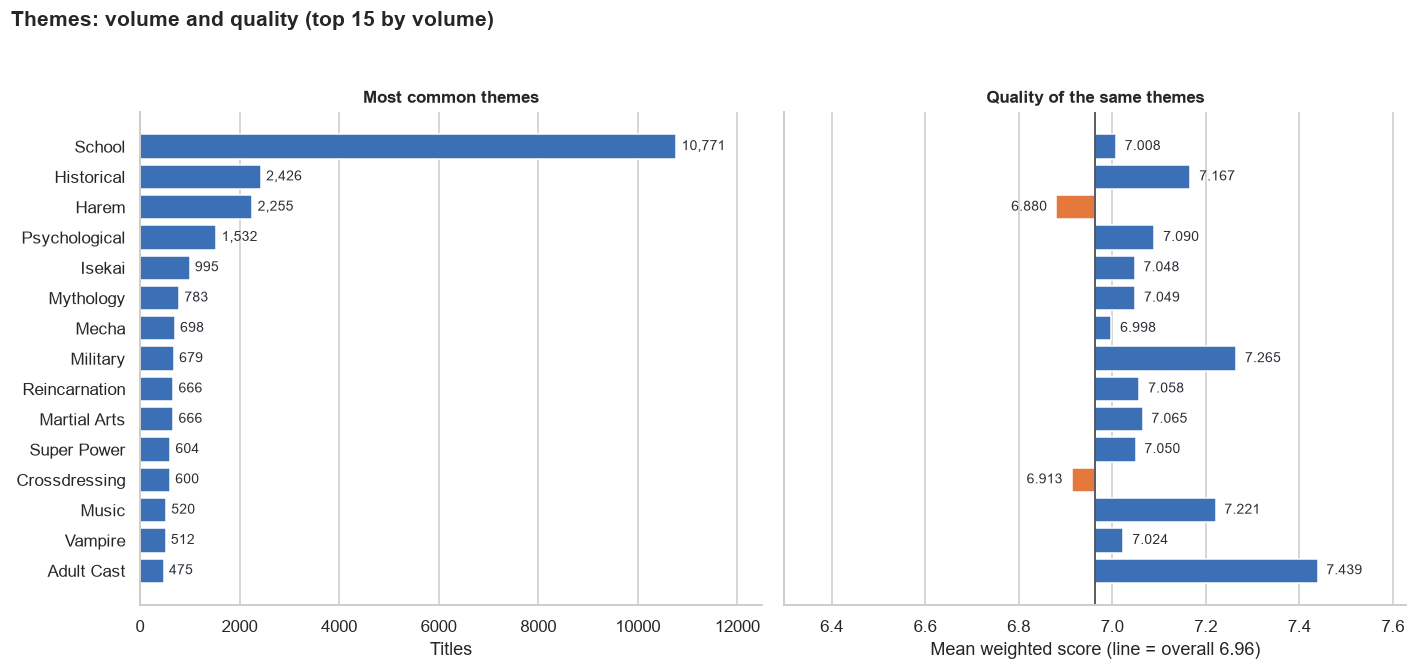

In [20]:
fig = mv.theme_summary(d)
plt.show()

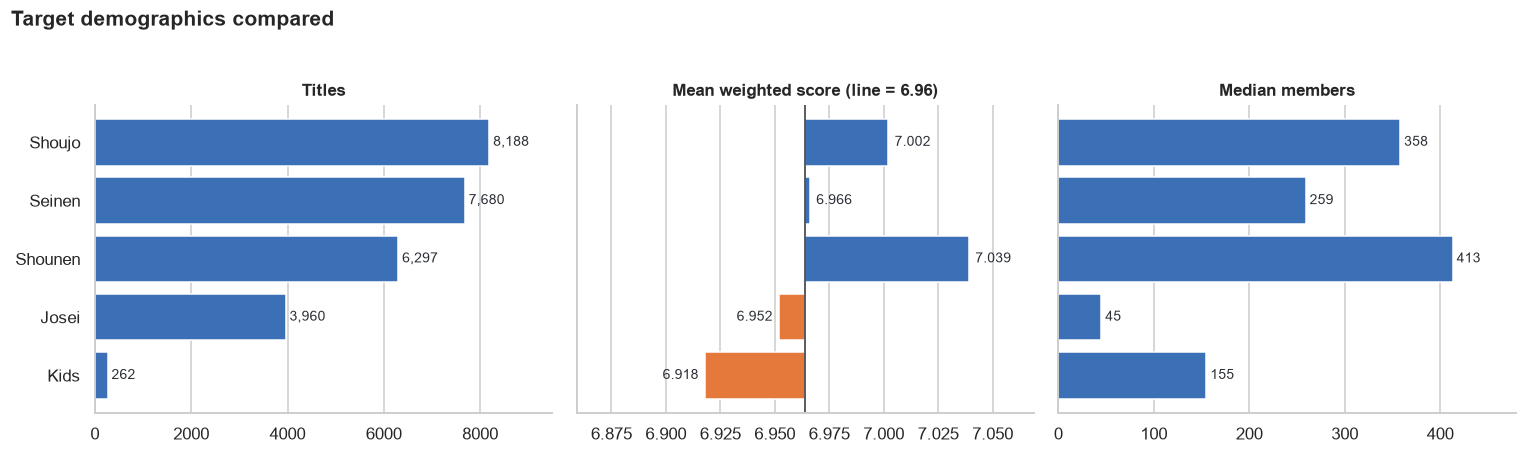

In [21]:
fig = mv.demographics(d)
plt.show()

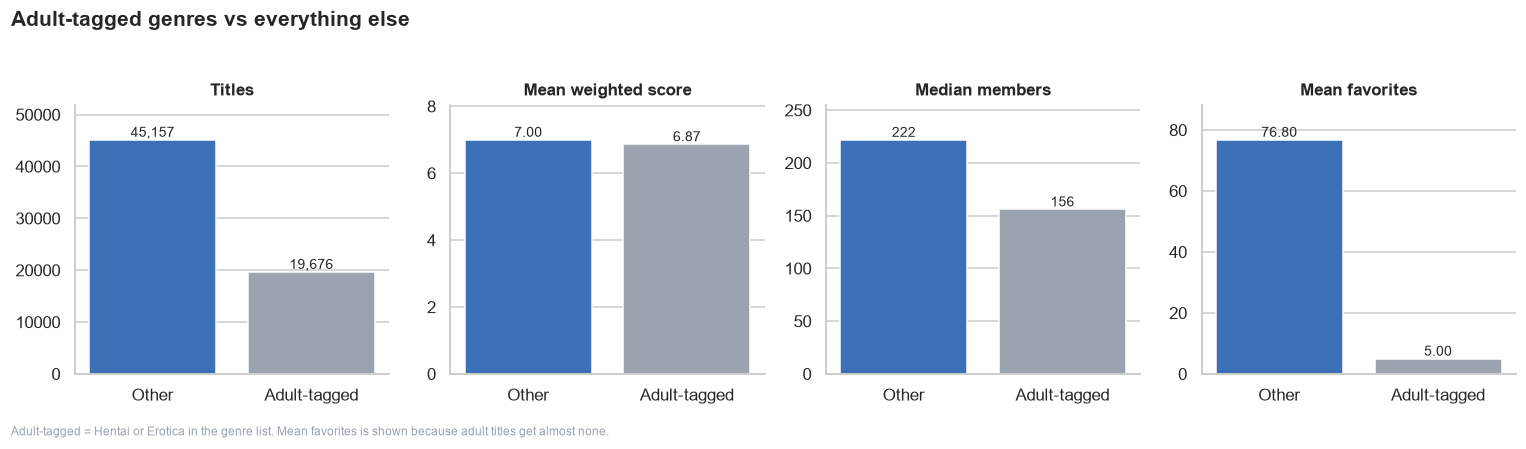

In [22]:
fig = mv.adult_vs_other(d)
plt.show()

## 6. Genre combinations

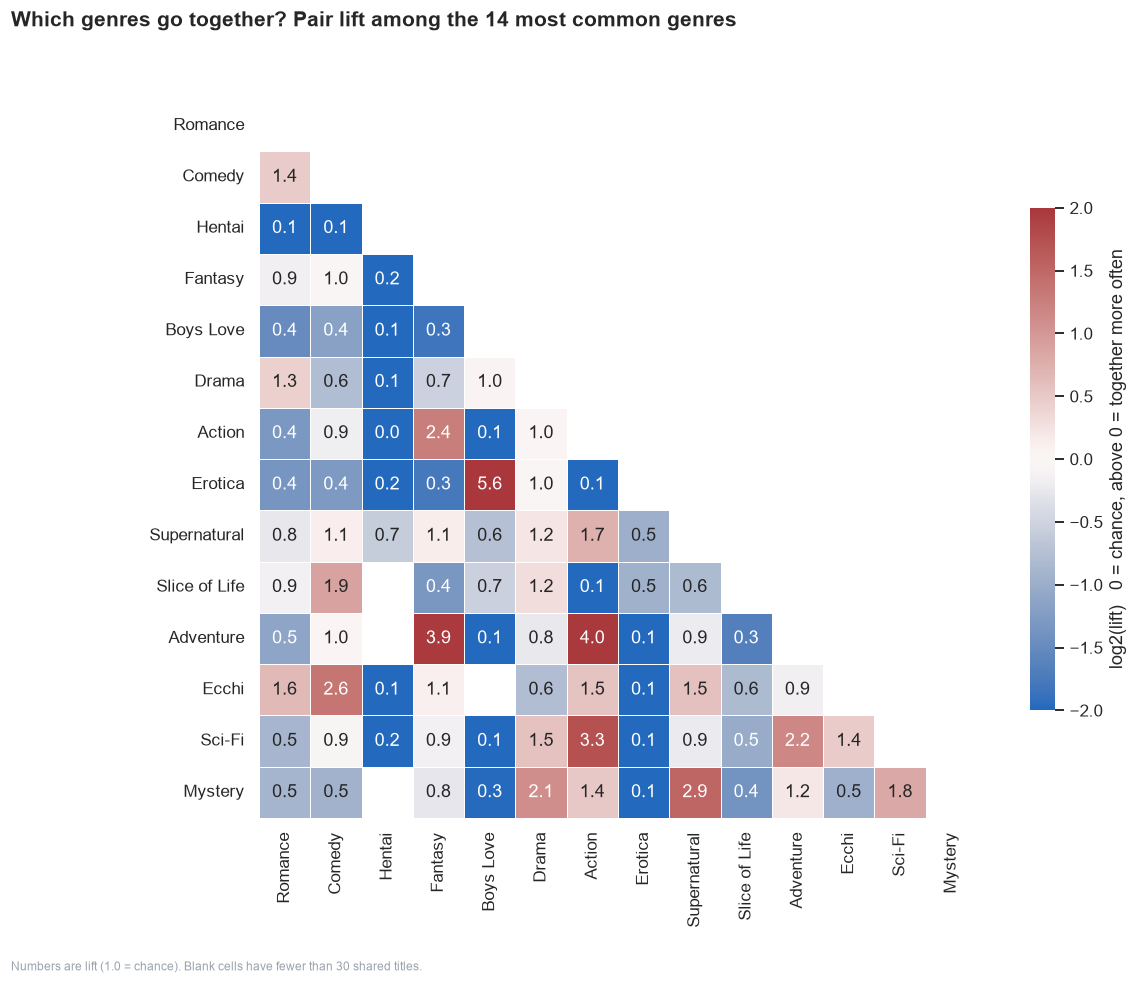

In [23]:
fig = mv.pair_lift_heatmap(d)
plt.show()

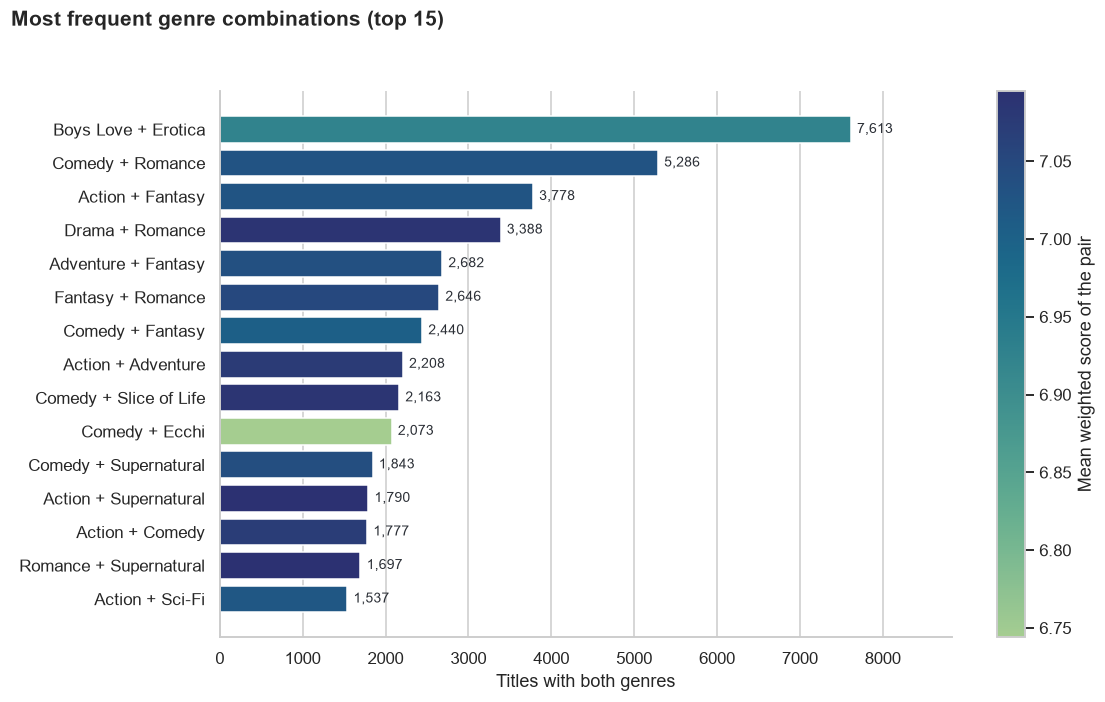

In [24]:
fig = mv.top_genre_pairs(d)
plt.show()

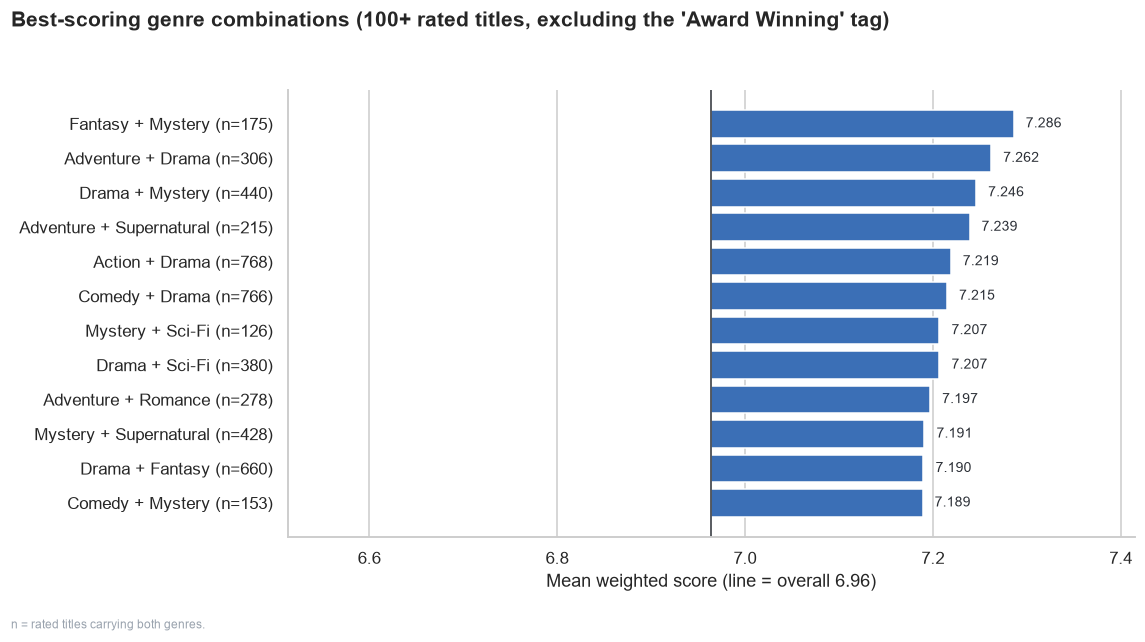

In [25]:
fig = mv.best_scoring_pairs(d)
plt.show()

## 7. Publication trends

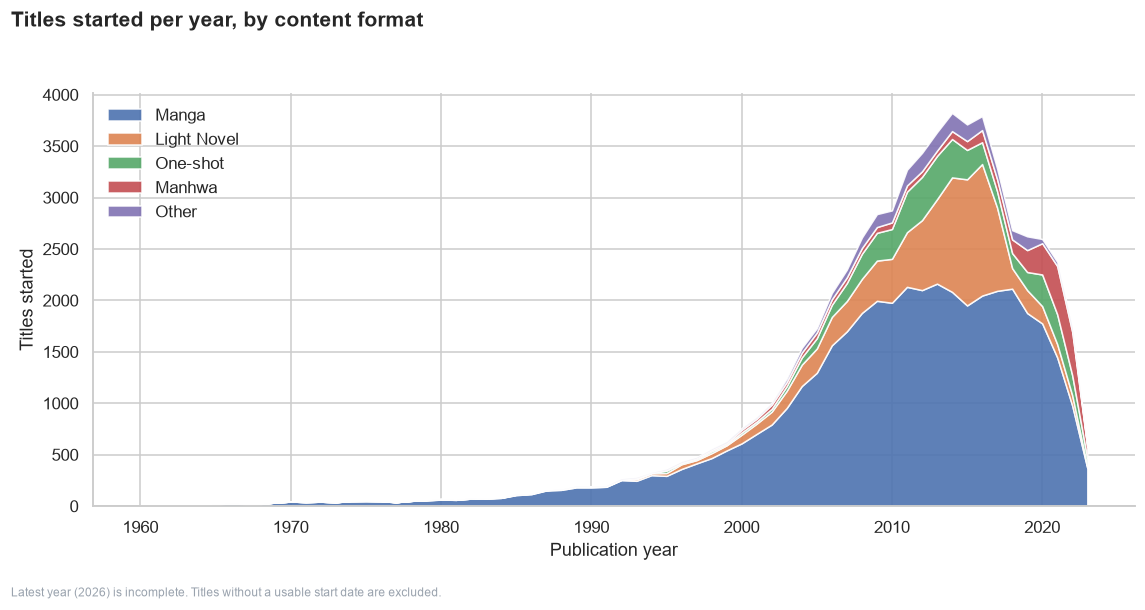

In [26]:
fig = mv.titles_per_year(d)
plt.show()

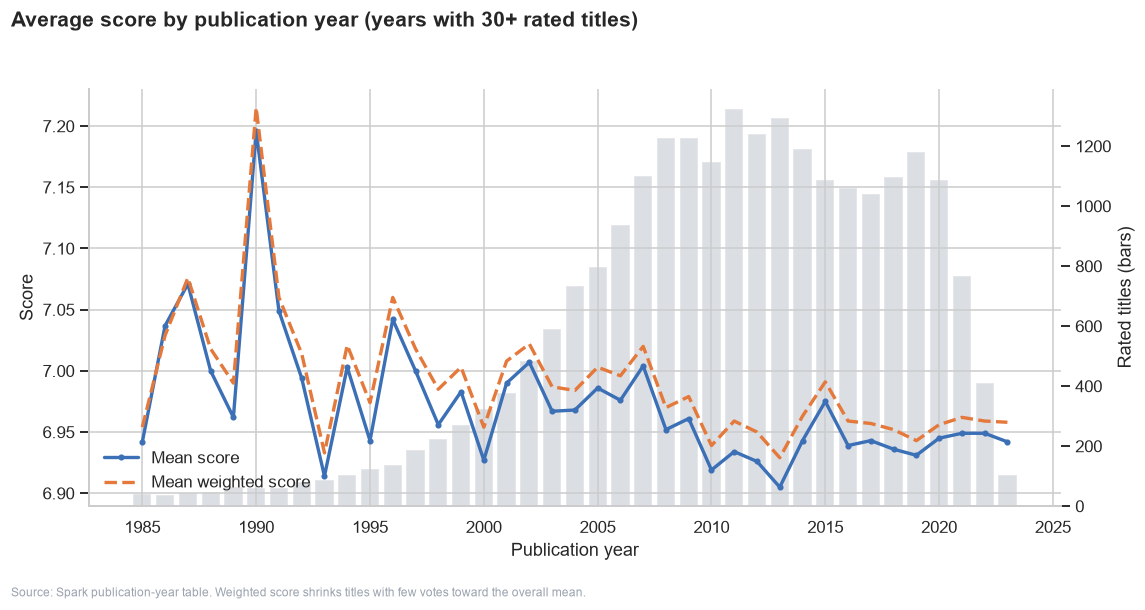

In [27]:
fig = mv.score_trend_by_year(d)
plt.show()

In [28]:
decades = (df.dropna(subset=["pub_year"])
             .assign(decade=lambda t: (t["pub_year"] // 10 * 10).astype(int))
             .groupby("decade")
             .agg(titles=("title", "size"), rated=("score", "count"), mean_score=("score", "mean"))
             .round(3))
decades

,titles,rated,mean_score
decade,,,
1920,1,0,NaN
1930,4,0,NaN
1940,16,7,6.541
1950,57,18,6.994
1960,170,62,7.066
1970,469,171,7.098
1980,1135,347,6.998
1990,3721,1331,6.994
2000,16961,7801,6.974


## 8. Popularity and ratings

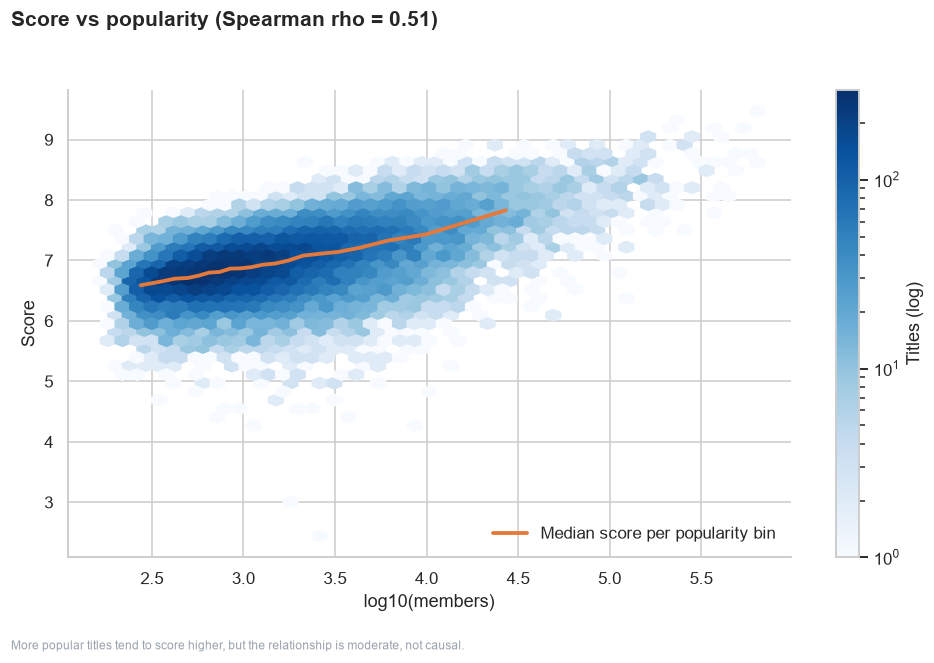

In [29]:
fig = mv.score_vs_popularity(d)
plt.show()

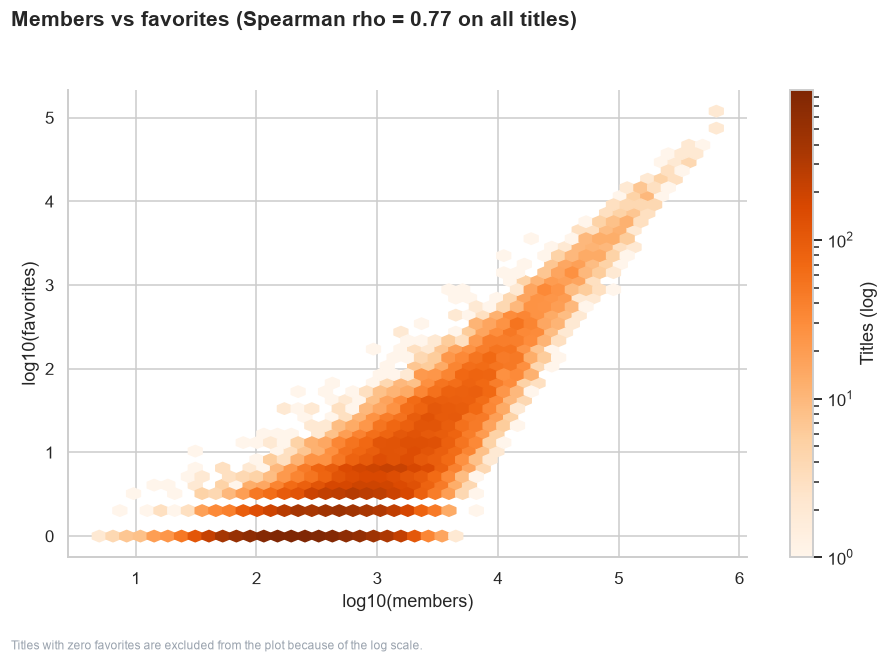

In [30]:
fig = mv.members_vs_favorites(d)
plt.show()

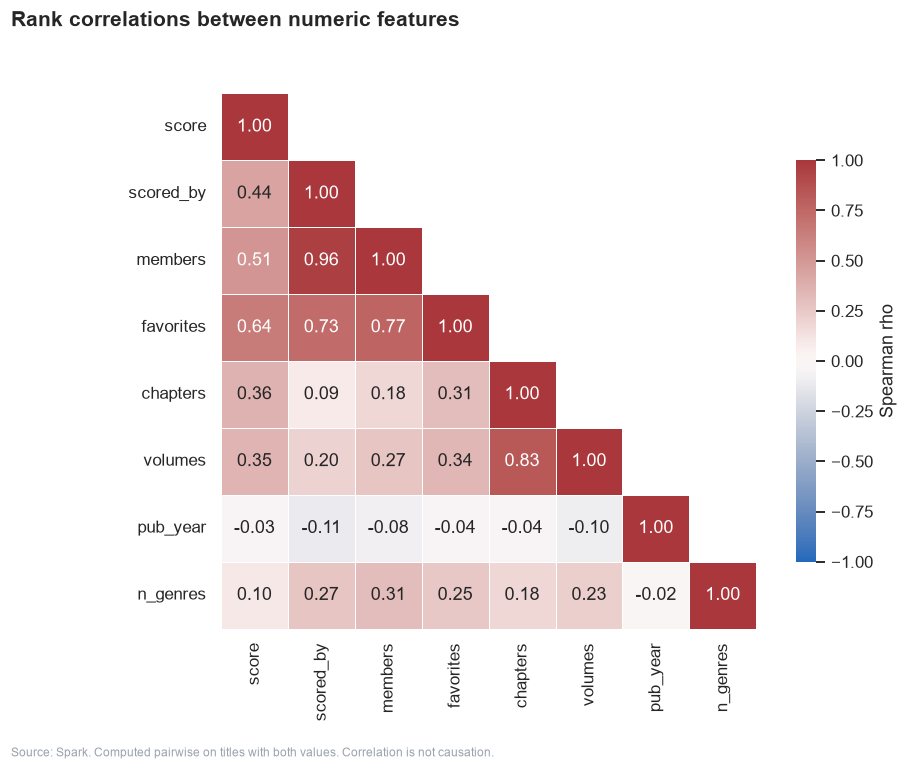

In [31]:
fig = mv.correlation_heatmap(d)
plt.show()

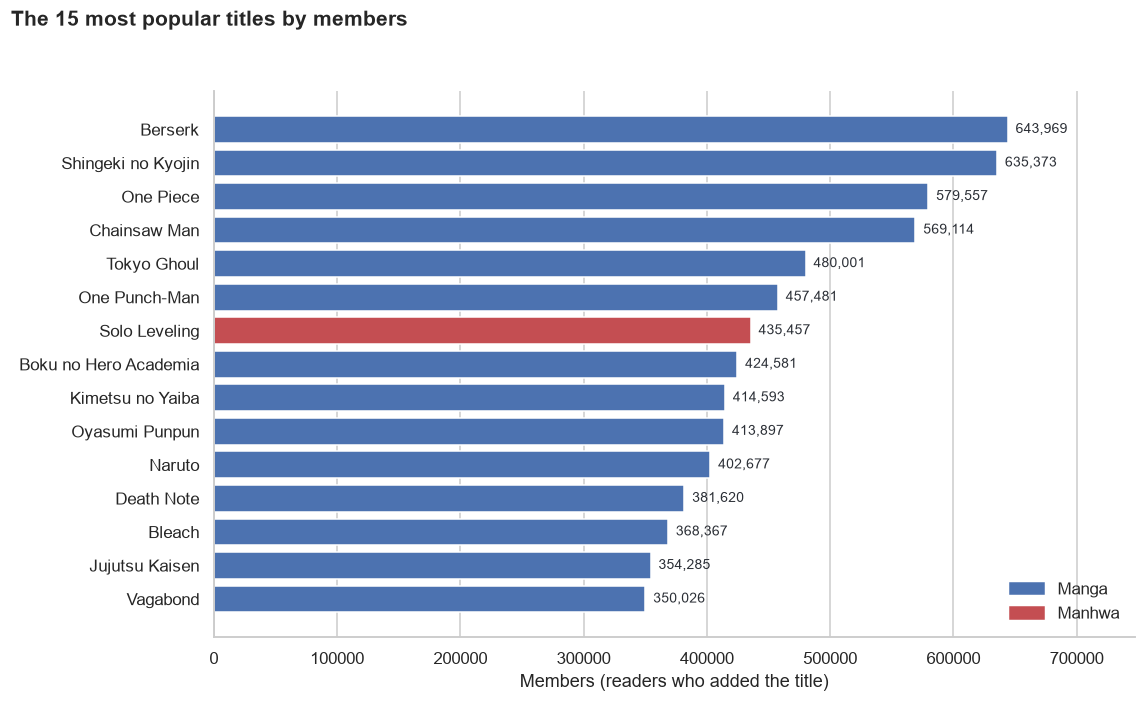

In [32]:
fig = mv.top_popular_titles(d)
plt.show()

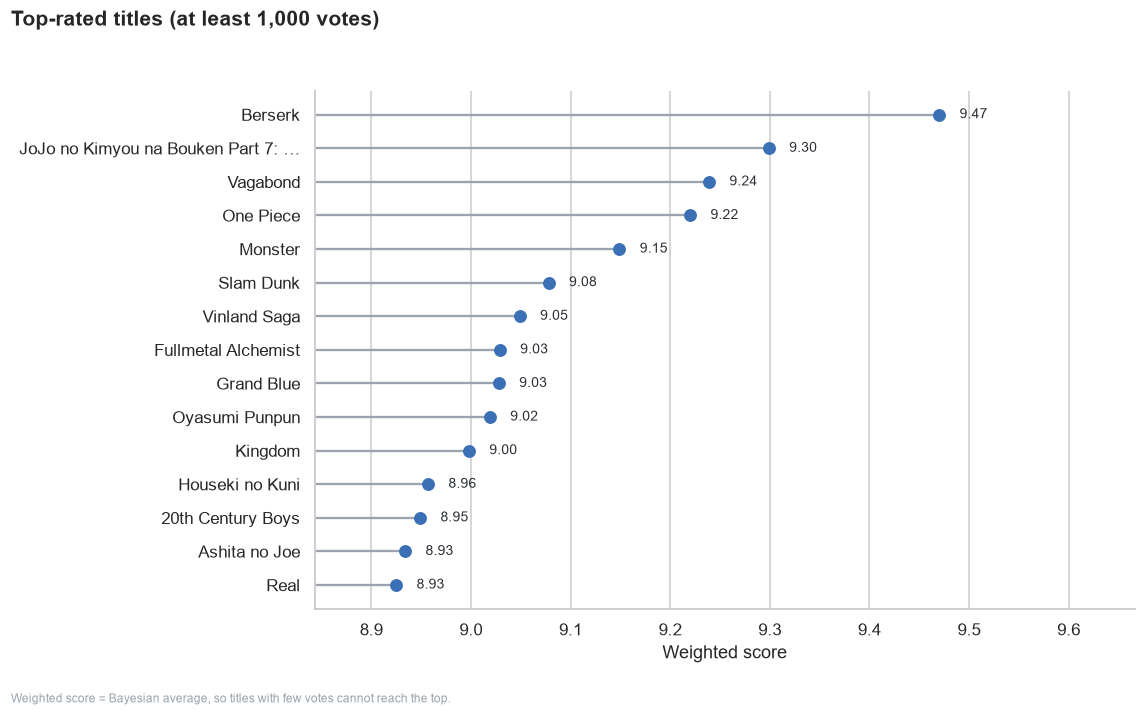

In [33]:
fig = mv.top_rated_titles(d)
plt.show()

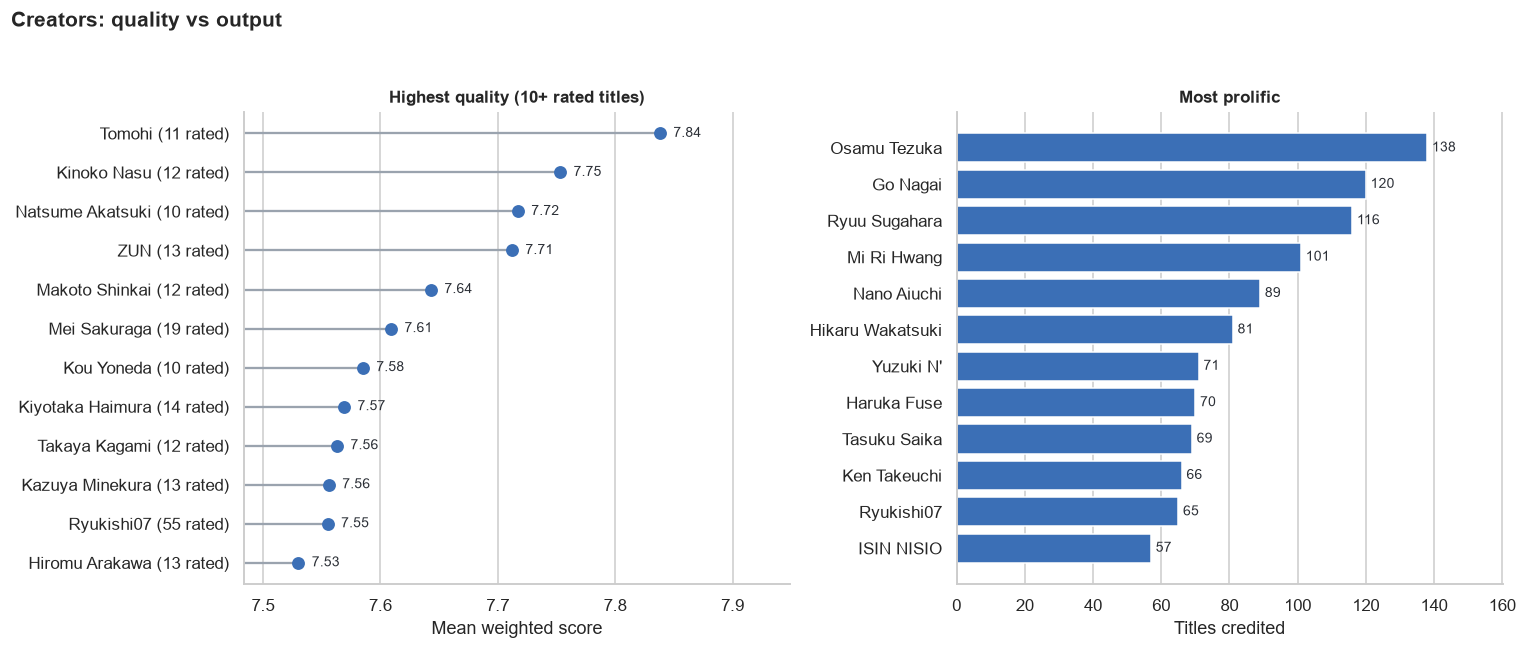

In [34]:
fig = mv.creators(d)
plt.show()

## 9. Save every chart

Writes all charts to `visualizations/` and refreshes `visualizations/INDEX.md`.

In [35]:
saved, skipped, failed = mv.build_all(d)
print(f"{len(saved)} saved, {len(skipped)} skipped, {len(failed)} failed")

Loaded 64,833 rows. Writing charts to D:\ember\visualizations
[SAVED]   01_missing_values.png
[SAVED]   02_rating_distribution.png
[SAVED]   03_format_composition.png
[SAVED]   04_score_by_format.png
[SAVED]   05_popularity_skew.png
[SAVED]   06_outliers.png
[SAVED]   07_score_vs_popularity.png
[SAVED]   08_members_vs_favorites.png
[SAVED]   09_titles_per_year_by_format.png
[SAVED]   10_score_trend_by_year.png
[SAVED]   11_correlation_heatmap.png
[SAVED]   12_genre_distribution.png
[SAVED]   13_genre_quality.png
[SAVED]   14_genre_popularity.png
[SAVED]   15_theme_summary.png
[SAVED]   16_demographics.png
[SAVED]   17_format_comparison.png
[SAVED]   18_adult_vs_other.png
[SAVED]   19_genre_pair_lift_heatmap.png
[SAVED]   20_top_genre_pairs.png
[SAVED]   21_best_scoring_pairs.png
[SAVED]   22_top_popular_titles.png
[SAVED]   23_top_rated_titles.png
[SAVED]   24_creators.png
Done: 24 saved, 0 skipped, 0 failed.
24 saved, 0 skipped, 0 failed
